# MSCS 634 – Project Deliverable 3
## Classification, Clustering, and Pattern Mining
### Dataset: IBM Telco Customer Churn (cleaned in Deliverable 1)

**Course:** MSCS 634
**Authors:** Pranavi Balakulla, Sandeep Reddy Banda, Sowmya Cheruku, Vineela Reddy Karnatakam
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

---

**Notebook roadmap**

* **Part A – Classification:** predict whether a customer will churn
  (Logistic Regression, Decision Tree, k-NN, Naïve Bayes, Random Forest), with **hyperparameter tuning** of the
  Decision Tree, evaluated with **confusion matrices, ROC curves, accuracy and F1**.
* **Part B – Clustering:** segment customers with **K-Means**, choose the number of clusters, visualise and explain
  the groups.
* **Part C – Association rule mining:** discover service and behaviour patterns with **Apriori** (cross-checked with
  **FP-Growth**), focusing on patterns that lead to churn.
* **Part D – Real-world application, challenges and conclusion.**

## 1. Setup and Data Loading

In [1]:
# ---------------------------------------------------------------
# Libraries
# ---------------------------------------------------------------
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# Classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Association rules
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
RANDOM_STATE = 42

In [2]:
# ---------------------------------------------------------------
# Consistent, colour-blind-safe chart styling (same look as Deliverable 1)
# ---------------------------------------------------------------
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
MUTED = "#b4b2a9"                      # neutral grey for baselines / "other"

# Fixed categorical order: a colour always follows the same entity, never its rank
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
STAY, LEAVE = CAT[0], CAT[1]           # blue = stayed, orange = churned (as in Deliverable 1)

SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

FIG_DIR = "Images"
os.makedirs(FIG_DIR, exist_ok=True)


def save(fig, name):
    # Save a figure into Images/ so it can be referenced from the README.
    fig.savefig(os.path.join(FIG_DIR, name))

In [3]:
# ---------------------------------------------------------------
# Load the cleaned dataset produced in Deliverable 1
# ---------------------------------------------------------------
# The file is stored in this repository; if it is missing, the identical copy
# from the Deliverable 1 repository on GitHub is used instead.
DATA_PATH = "telco_churn_cleaned.csv"
DATA_URL = "https://raw.githubusercontent.com/pranavibalakulla/MSCS_634_Project_Deliverable_1/main/telco_churn_cleaned.csv"

source = DATA_PATH if os.path.exists(DATA_PATH) else DATA_URL
df = pd.read_csv(source)
print(f"Loaded from: {source}")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}   Missing values: {int(df.isna().sum().sum())}")
df.head(3)

Loaded from: telco_churn_cleaned.csv
Rows: 7,043   Columns: 24   Missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag,tenure_group,NumServices
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,2
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48,4
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12,4


---
# Part A – Classification: Predicting Customer Churn

**Goal:** predict `Churn` (Yes = the customer left) so the company can contact at-risk customers *before* they leave.

### A.1 Feature preparation

* **Removed:** `customerID` (identifier), `Churn` / `Churn_flag` (the target), `tenure_group` (duplicate of `tenure`),
  and `gender` and `PhoneService`, which Deliverable 1 showed have **no statistically significant association** with
  churn (Cramér's V ≈ 0.01, p > 0.3).
* **Encoding:** categorical columns are one-hot encoded (`drop_first=True`).
* **Scaling:** numeric columns are standardised **inside each model pipeline**, so scaling is learned from training
  folds only (no leakage). Scaling matters for distance- and gradient-based models (k-NN, Logistic Regression).
* **Class imbalance (≈ 73% stay / 27% churn):** we use a **stratified** split and stratified folds so every fold keeps
  the same churn rate, and `class_weight="balanced"` where the algorithm supports it.

In [4]:
# ---------------------------------------------------------------
# A.1 Build the feature matrix and target
# ---------------------------------------------------------------
drop_cols = ["customerID", "Churn", "Churn_flag", "tenure_group", "gender", "PhoneService"]
X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True, dtype=float)
y = df["Churn_flag"]

print(f"Features: {X.shape[1]}   Rows: {X.shape[0]:,}   Churn rate: {y.mean():.1%}")
list(X.columns)

Features: 22   Rows: 7,043   Churn rate: 26.5%


['tenure',
 'MonthlyCharges',
 'TotalCharges',
 'NumServices',
 'SeniorCitizen_Yes',
 'Partner_Yes',
 'Dependents_Yes',
 'MultipleLines_Yes',
 'InternetService_Fiber optic',
 'InternetService_No',
 'OnlineSecurity_Yes',
 'OnlineBackup_Yes',
 'DeviceProtection_Yes',
 'TechSupport_Yes',
 'StreamingTV_Yes',
 'StreamingMovies_Yes',
 'Contract_One year',
 'Contract_Two year',
 'PaperlessBilling_Yes',
 'PaymentMethod_Credit card (automatic)',
 'PaymentMethod_Electronic check',
 'PaymentMethod_Mailed check']

In [5]:
# ---------------------------------------------------------------
# A.2 Stratified 80/20 train/test split
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} rows (churn {y_train.mean():.1%})   "
      f"Test: {len(X_test):,} rows (churn {y_test.mean():.1%})")

Train: 5,634 rows (churn 26.5%)   Test: 1,409 rows (churn 26.5%)


### A.2 Classification models

| Model | Why it is included | Settings |
|---|---|---|
| **Logistic Regression** | Interpretable linear baseline that outputs probabilities | `class_weight="balanced"` |
| **Decision Tree (default)** | Human-readable rules; shown *before* tuning to demonstrate overfitting | scikit-learn defaults (grows until leaves are pure) |
| **k-Nearest Neighbours** | Instance-based: a customer looks like their nearest neighbours | `k = 25` (a larger *k* smooths out noise on 5,600 training rows) |
| **Naïve Bayes** | Fast probabilistic model; assumes independent features | `GaussianNB` |
| **Random Forest** | Ensemble of trees; robust to noise and interactions | 300 trees, `min_samples_leaf=5`, `class_weight="balanced"` |
| **Decision Tree (tuned)** | Same algorithm after **GridSearchCV** (Section A.3) | best parameters from the search |

In [6]:
# ---------------------------------------------------------------
# A.3 Define the models (each in a pipeline with standardisation)
# ---------------------------------------------------------------
base_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree (default)": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "k-NN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
}

# Fixed colour per model in every chart (orange is reserved for "churned")
MODEL_COLORS = {"Logistic Regression": CAT[0], "Decision Tree (default)": MUTED,
                "Decision Tree (tuned)": CAT[2], "k-NN": CAT[3], "Naive Bayes": CAT[4],
                "Random Forest": CAT[5]}

# 5-fold stratified cross-validation on the TRAINING set
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in base_models.items():
    res = cross_validate(model, X_train, y_train, cv=skf, scoring=["accuracy", "f1", "roc_auc"])
    cv_rows.append({"model": name,
                    "CV accuracy": res["test_accuracy"].mean(),
                    "CV F1": res["test_f1"].mean(), "CV F1 std": res["test_f1"].std(),
                    "CV ROC-AUC": res["test_roc_auc"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(4)

,CV accuracy,CV F1,CV F1 std,CV ROC-AUC
model,,,,
Logistic Regression,0.7496,0.6294,0.0225,0.8462
Decision Tree (default),0.7284,0.4920,0.0135,0.6557
k-NN,0.7874,0.5839,0.0165,0.8258
Naive Bayes,0.7485,0.6203,0.0166,0.8312
Random Forest,0.7774,0.6326,0.0247,0.8433


### A.3 Hyperparameter tuning – Decision Tree with GridSearchCV

**Technique:** an exhaustive **grid search** with **5-fold stratified cross-validation** (`GridSearchCV`). Every
combination of the parameters below is trained on 4 folds and scored on the 5th; the combination with the best average
score is selected and refit on the full training set.

**Why tune the Decision Tree?** The default tree grows until every leaf is pure, which memorises the training data
(overfitting). Its parameters directly control model complexity, and a tuned tree stays readable, so the business can
see *why* a customer is flagged.

| Parameter | Values searched | What it controls |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 7, 8, 10, 12, None | Maximum number of questions from root to leaf (complexity) |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80 | Minimum customers in a leaf; larger = smoother, less noise-fitting |
| `criterion` | gini, entropy | How split quality is measured |
| `class_weight` | None, balanced | Whether churners are up-weighted to offset the 73/27 imbalance |

**Scoring metric: F1 for the churn class.** Accuracy is misleading on imbalanced data (predicting "no churn" for
everyone already gives 73%). F1 balances **precision** (how many flagged customers really churn) and **recall** (how
many churners we catch). That is 10 × 6 × 2 × 2 = **240 combinations × 5 folds = 1,200 fits**.

In [7]:
# ---------------------------------------------------------------
# A.4 Grid search
# ---------------------------------------------------------------
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 7, 8, 10, 12, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    scoring="f1", cv=skf, n_jobs=-1, return_train_score=True)
start = time.time()
grid.fit(X_train, y_train)
print(f"Grid search finished in {time.time() - start:.1f} s ({len(grid.cv_results_['params'])} combinations x 5 folds)")
print("Best parameters :", grid.best_params_)
print(f"Best CV F1      : {grid.best_score_:.4f}")

# CV score of the default tree, for comparison
print(f"Default tree CV F1: {cv_table.loc['Decision Tree (default)', 'CV F1']:.4f}")

Grid search finished in 29.9 s (240 combinations x 5 folds)
Best parameters : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 40}
Best CV F1      : 0.6167
Default tree CV F1: 0.4920


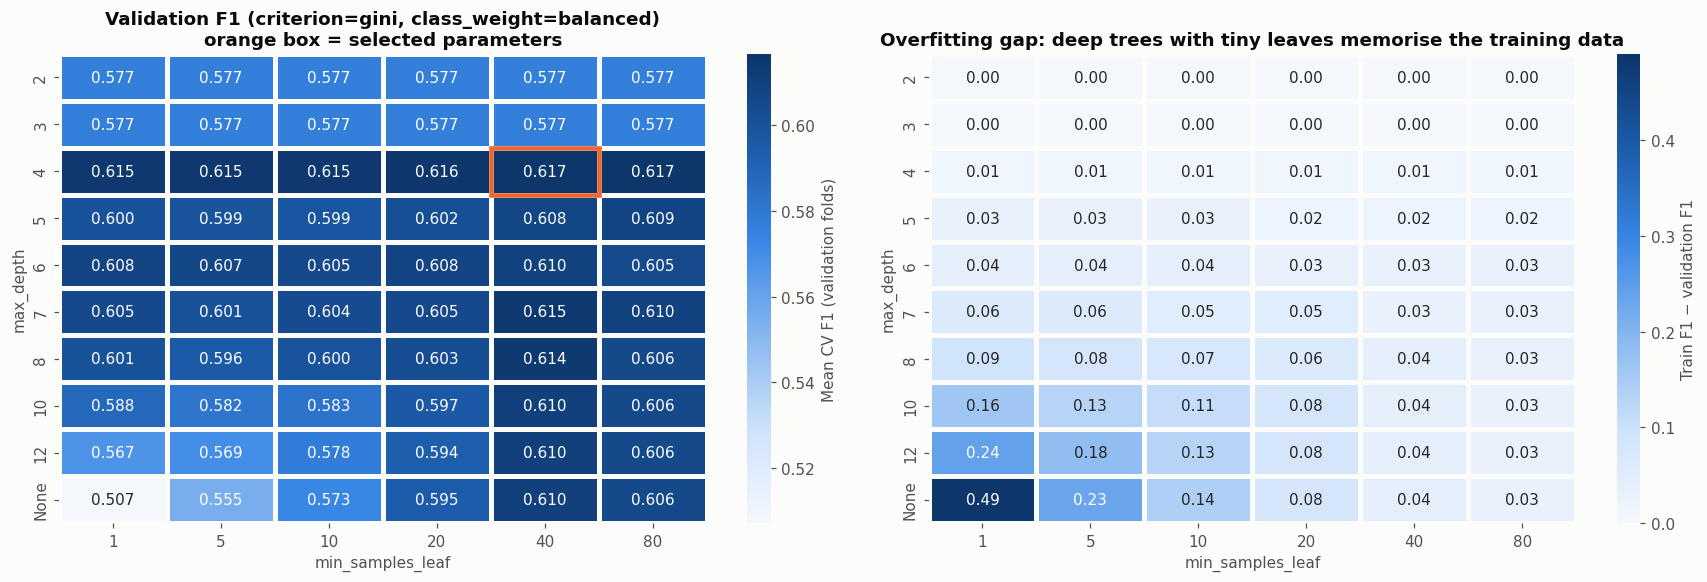

In [8]:
# ---------------------------------------------------------------
# A.5 Visualise the search: CV F1 for every max_depth x min_samples_leaf
#     (using the best criterion and class_weight)
# ---------------------------------------------------------------
cvr = pd.DataFrame(grid.cv_results_)
best = grid.best_params_
as_label = lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v)
mask = (cvr["param_criterion"] == best["criterion"]) & \
       (cvr["param_class_weight"].map(as_label) == as_label(best["class_weight"]))
sub = cvr[mask].copy()
sub["max_depth"] = sub["param_max_depth"].map(lambda v: as_label(v if v is None or pd.isna(v) else int(v)))
sub["min_samples_leaf"] = sub["param_min_samples_leaf"].astype(int)
depth_order = [str(d) for d in param_grid["max_depth"]]
heat = sub.pivot(index="max_depth", columns="min_samples_leaf", values="mean_test_score").reindex(depth_order)
gap = sub.pivot(index="max_depth", columns="min_samples_leaf", values="mean_train_score").reindex(depth_order) - heat
gap = gap.round(2) + 0.0          # + 0.0 turns "-0.00" into "0.00" for display

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
sns.heatmap(heat, annot=True, fmt=".3f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Mean CV F1 (validation folds)"}, ax=axes[0])
r = depth_order.index(str(best["max_depth"]))
c = list(heat.columns).index(best["min_samples_leaf"])
axes[0].add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor=CAT[1], lw=3))
axes[0].set_title(f"Validation F1 (criterion={best['criterion']}, class_weight={best['class_weight']})"
                  "\norange box = selected parameters")
axes[0].grid(False)

sns.heatmap(gap, annot=True, fmt=".2f", cmap=SEQ_BLUE, linewidths=2, linecolor=SURFACE,
            cbar_kws={"label": "Train F1 − validation F1"}, ax=axes[1])
axes[1].set_title("Overfitting gap: deep trees with tiny leaves memorise the training data")
axes[1].grid(False)
for ax in axes:
    ax.set_ylabel("max_depth")
    ax.set_xlabel("min_samples_leaf")
fig.tight_layout()
save(fig, "01_hyperparameter_tuning_heatmap.png")
plt.show()

**Explaining the chosen parameters**

| Parameter | Chosen value | Why (from the heatmaps) |
|---|---|---|
| `max_depth` | **4** | Depths 2–3 are too simple (CV F1 0.577 – **underfitting**). Depth 4 gives the best validation F1 (**0.617**). Deeper trees score no better on validation folds while the train–validation gap keeps growing — up to **0.49** for an unlimited tree with 1-customer leaves, which is the default setting (**overfitting**). |
| `min_samples_leaf` | **40** | At depth 4 all leaf sizes are close, and 40 scores best. Larger leaves also protect deeper trees from memorising noise (the right-hand columns stay stable). Each final rule is based on at least 40 customers. |
| `criterion` | **gini** | Gini and entropy gave near-identical results; gini scored slightly higher. |
| `class_weight` | **balanced** | Up-weights churners so the tree does not ignore the minority class, raising recall. |

**Effect of tuning:** cross-validated F1 rose from **0.492** (default tree) to **0.617** (+0.125). On the test set (Section A.4)
F1 rises from 0.499 to 0.621, recall from 51% to 78%, and ROC-AUC from 0.659 to 0.816. Training F1 fell from 0.996 to 0.621,
so the tuned tree no longer memorises the training data.

The tuned tree is also easy to explain: its first questions are **"Two-year contract?" → "One-year contract?" → "Fiber
optic internet?"** Contract type alone accounts for about 71% of the tree's importance, followed by fiber optic (12%)
and tenure (10%). (Because of class balancing, the root node shows a 50/50 split.)

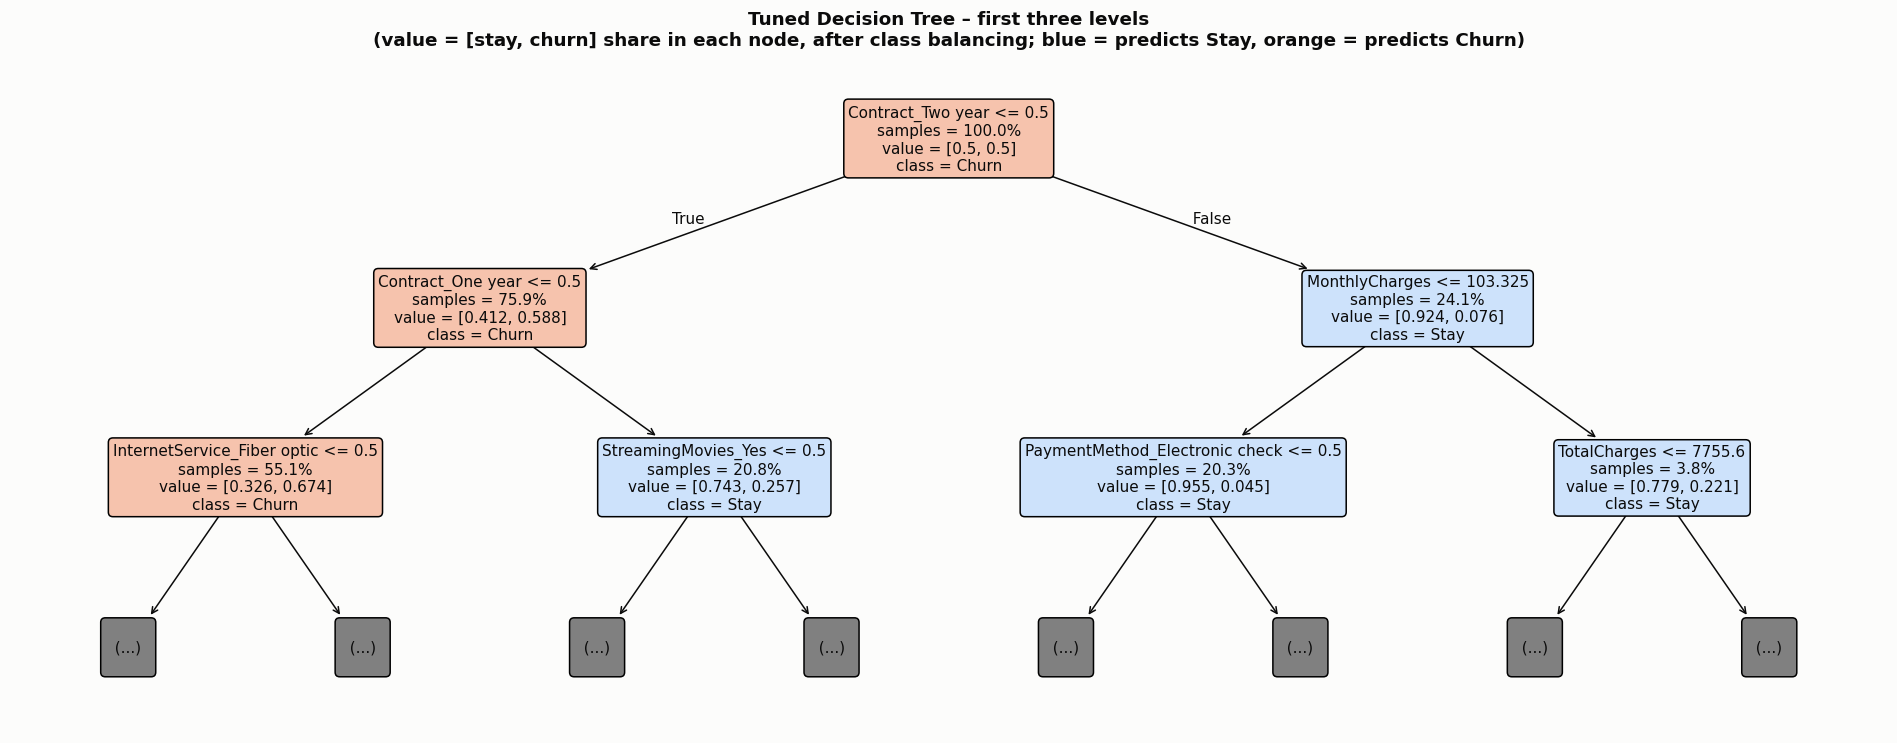

Top 8 features used by the tuned tree:
Contract_Two year                 43.5%
Contract_One year                 27.2%
InternetService_Fiber optic       12.0%
tenure                            10.1%
StreamingMovies_Yes                3.7%
MonthlyCharges                     1.7%
TotalCharges                       1.1%
PaymentMethod_Electronic check     0.8%
dtype: object


In [9]:
# ---------------------------------------------------------------
# A.6 The tuned tree's top levels (readable churn rules)
# ---------------------------------------------------------------
tuned_tree = grid.best_estimator_
fig, ax = plt.subplots(figsize=(22, 8))
nodes = plot_tree(tuned_tree, max_depth=2, feature_names=list(X.columns), class_names=["Stay", "Churn"],
                  filled=True, rounded=True, impurity=False, proportion=True, fontsize=10, ax=ax)
# Recolour nodes to match the rest of the project: blue = predicted Stay, orange = predicted Churn
for node in nodes:
    box = node.get_bbox_patch()
    if box is not None and "class = Churn" in node.get_text():
        box.set_facecolor("#f6c3ad")
    elif box is not None and "class = Stay" in node.get_text():
        box.set_facecolor("#cde2fb")
ax.set_title("Tuned Decision Tree – first three levels\n(value = [stay, churn] share in each node, after class balancing; "
             "blue = predicts Stay, orange = predicts Churn)")
save(fig, "02_tuned_tree_top_levels.png")
plt.show()

imp = pd.Series(tuned_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 8 features used by the tuned tree:")
print((imp[:8] * 100).round(1).astype(str) + "%")

### A.4 Test-set evaluation: accuracy, precision, recall, F1 and ROC-AUC

All six models are fitted on the full training set and evaluated once on the untouched, stratified test set.

In [10]:
# ---------------------------------------------------------------
# A.7 Fit every model and score it on the test set
# ---------------------------------------------------------------
final_models = dict(base_models)
final_models["Decision Tree (tuned)"] = make_pipeline(StandardScaler(), DecisionTreeClassifier(
    random_state=RANDOM_STATE, **grid.best_params_))
MODEL_ORDER = ["Logistic Regression", "Decision Tree (default)", "Decision Tree (tuned)",
               "k-NN", "Naive Bayes", "Random Forest"]

rows, probas, preds = [], {}, {}
for name in MODEL_ORDER:
    model = final_models[name].fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probas[name], preds[name] = p, yhat
    rows.append({"model": name,
                 "Accuracy": accuracy_score(y_test, yhat),
                 "Precision": precision_score(y_test, yhat),
                 "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "Train F1": f1_score(y_train, model.predict(X_train))})
results = pd.DataFrame(rows).set_index("model")
results.sort_values("F1", ascending=False).round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
model,,,,,,
Random Forest,0.7764,0.5601,0.7353,0.6358,0.8432,0.7588
Decision Tree (tuned),0.7459,0.5140,0.7834,0.6208,0.8159,0.6212
Logistic Regression,0.7374,0.5034,0.7834,0.6130,0.8415,0.6338
Naive Bayes,0.7381,0.5045,0.7513,0.6037,0.8229,0.6212
k-NN,0.7757,0.5806,0.5588,0.5695,0.8154,0.6148
Decision Tree (default),0.7310,0.4935,0.5053,0.4993,0.6594,0.9956


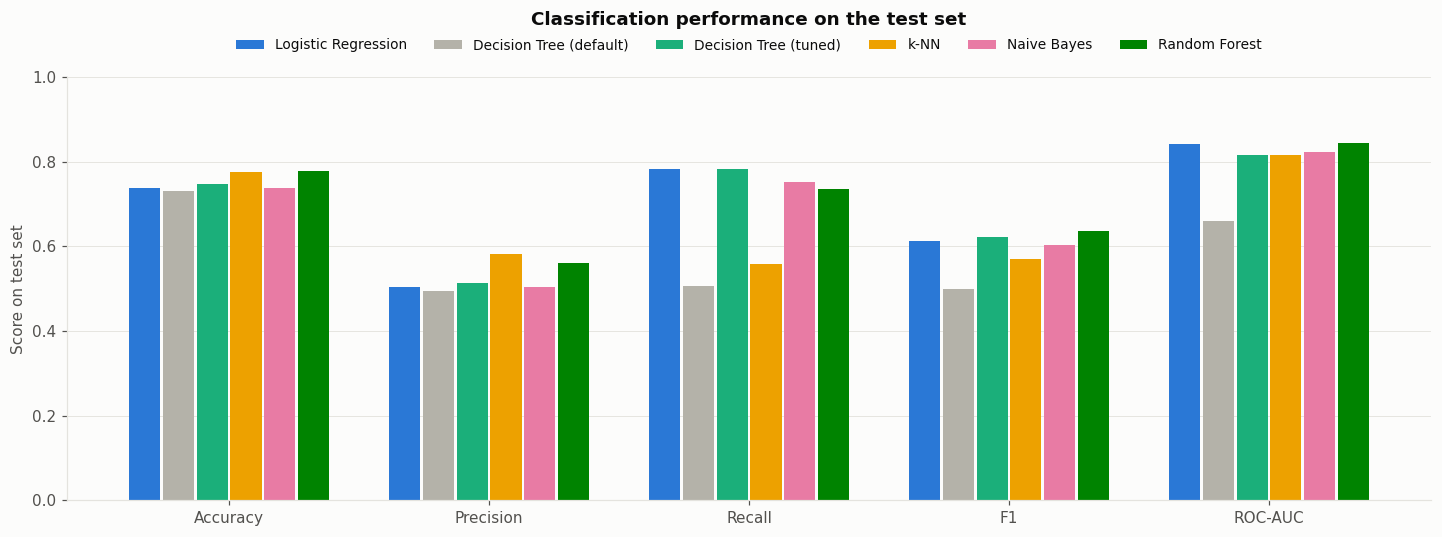

In [11]:
# ---------------------------------------------------------------
# A.8 Visual comparison of the test metrics
# ---------------------------------------------------------------
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(16, 5))
w = 0.13
x = np.arange(len(metrics))
for i, name in enumerate(MODEL_ORDER):
    vals = results.loc[name, metrics].values
    ax.bar(x + (i - 2.5) * w, vals, width=w * 0.92, color=MODEL_COLORS[name], label=name)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score on test set")
ax.grid(axis="x", visible=False)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.12), fontsize=9)
ax.set_title("Classification performance on the test set", pad=34)
save(fig, "03_classification_metrics.png")
plt.show()

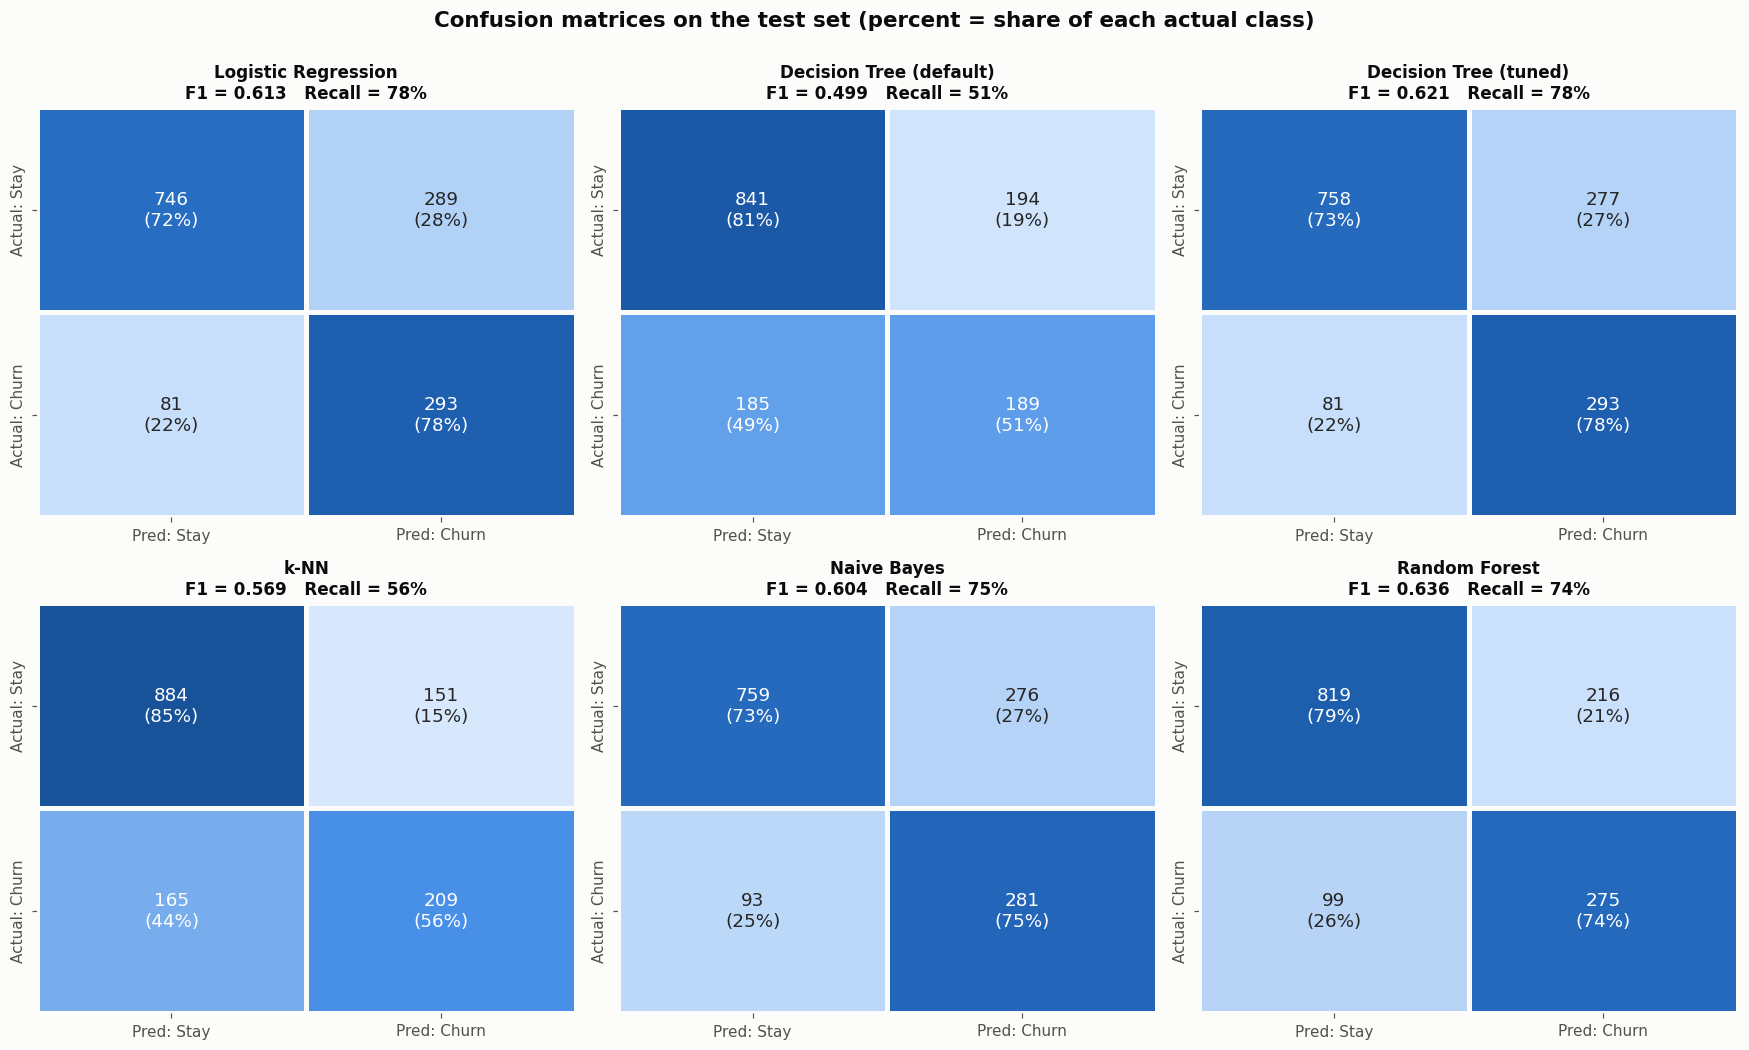

In [12]:
# ---------------------------------------------------------------
# A.9 Confusion matrices (counts and % of each actual class)
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, name in zip(axes.flat, MODEL_ORDER):
    cm = confusion_matrix(y_test, preds[name])
    pct = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=labels, fmt="", cmap=SEQ_BLUE, vmin=0, vmax=1, cbar=False,
                linewidths=2, linecolor=SURFACE, annot_kws={"size": 12}, ax=ax,
                xticklabels=["Pred: Stay", "Pred: Churn"], yticklabels=["Actual: Stay", "Actual: Churn"])
    ax.set_title(f"{name}\nF1 = {results.loc[name, 'F1']:.3f}   Recall = {results.loc[name, 'Recall']:.0%}",
                 fontsize=11)
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set (percent = share of each actual class)",
             fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "04_confusion_matrices.png")
plt.show()

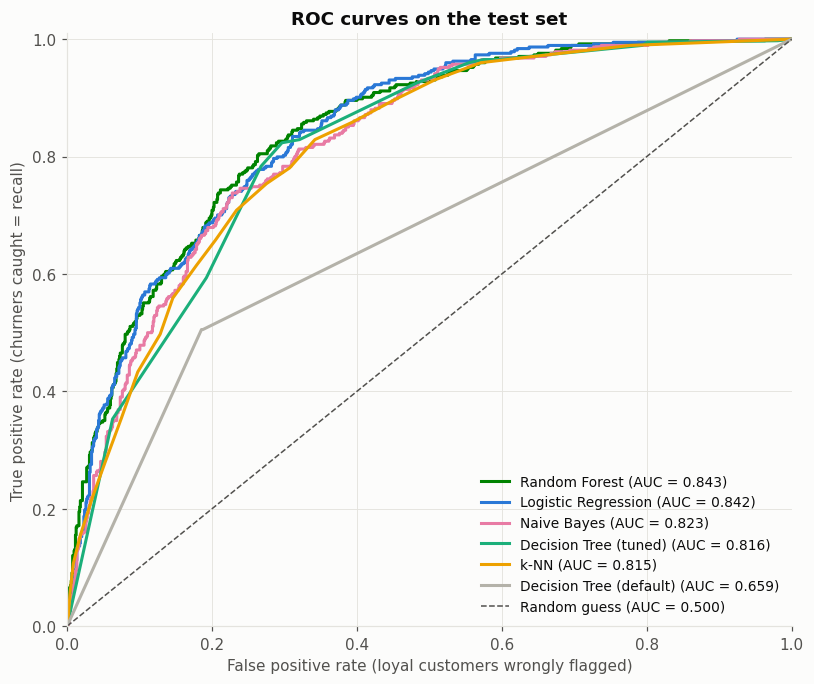

In [13]:
# ---------------------------------------------------------------
# A.10 ROC curves
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 7))
for name in sorted(MODEL_ORDER, key=lambda n: -results.loc[n, "ROC-AUC"]):
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[name], label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=INK_2, lw=1, label="Random guess (AUC = 0.500)")
ax.set_xlabel("False positive rate (loyal customers wrongly flagged)")
ax.set_ylabel("True positive rate (churners caught = recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
save(fig, "05_roc_curves.png")
plt.show()

### A.5 Classification insights

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.776** | 0.560 | 0.735 | **0.636** | **0.843** |
| Decision Tree (tuned) | 0.746 | 0.514 | **0.783** | 0.621 | 0.816 |
| Logistic Regression | 0.737 | 0.503 | **0.783** | 0.613 | 0.842 |
| Naive Bayes | 0.738 | 0.505 | 0.751 | 0.604 | 0.823 |
| k-NN | 0.776 | **0.581** | 0.559 | 0.570 | 0.815 |
| Decision Tree (default) | 0.731 | 0.494 | 0.505 | 0.499 | 0.659 |

* **Best model: Random Forest** — highest F1 (0.636), ROC-AUC (0.843) and accuracy (0.776). It catches **74% of
  churners** (275 of 374 in the test set) while keeping the best balance with precision.
* **Logistic Regression is almost as good** (ROC-AUC 0.842, recall 78%) and is fully interpretable, which makes it a
  strong, simple alternative.
* **Hyperparameter tuning turned the weakest model into one of the best:** the tuned Decision Tree catches 293 of 374
  churners (78%) with an F1 of 0.621, versus 0.499 for the default tree.
* **Accuracy is misleading here.** k-NN ties Random Forest on accuracy (0.776) but misses **44% of churners**
  (165 of 374), because it cannot use class weights and leans towards the majority class. That is why F1, recall and
  ROC-AUC were used to choose models.
* **Naïve Bayes** performs reasonably (F1 0.604) even though its independence assumption is violated (contract,
  tenure and charges are correlated).
* **Precision–recall trade-off:** the class-weighted models flag roughly 490–580 customers to catch 275–293 churners
  (precision 0.50–0.56), so about **one in two flagged customers really churns**. For a retention campaign (a call or a small discount) that is
  usually a good trade. The ROC curves show how the threshold can be moved if contacts are more expensive.
* The strongest predictors — **contract type, fiber-optic internet and tenure** — match what the EDA in Deliverable 1
  found.

*Note: Random Forest uses random sampling internally, so its exact scores can differ slightly between scikit-learn
versions (we observed F1 between 0.63 and 0.64). The ranking of the models and the conclusions do not change.*

---
# Part B – Clustering: Customer Segmentation with K-Means

**Goal:** find natural customer groups **without using the churn label**, then check how churn differs between groups.

**Features used:** `tenure` (loyalty), `MonthlyCharges` (spend) and `NumServices` (how many services the customer
uses). These three describe *relationship length, value and engagement*, and are all numeric, which suits K-Means'
distance-based approach. They are **standardised** first, otherwise `MonthlyCharges` (range ≈ 18–119) would dominate
`NumServices` (range 1–9).

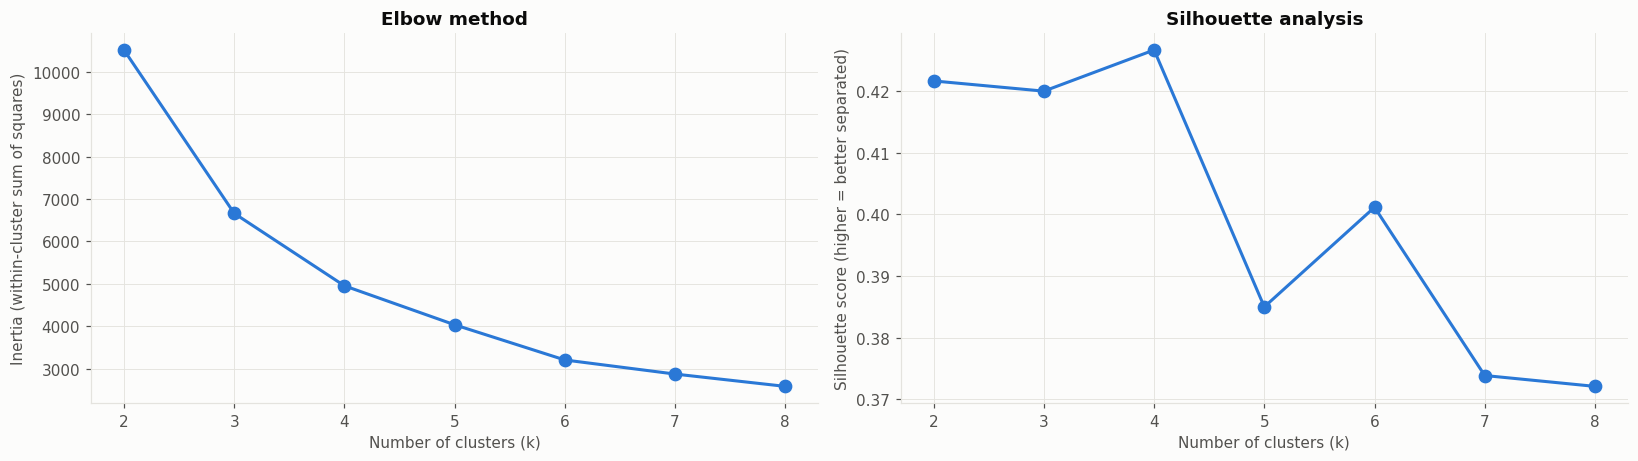

k,2,3,4,5,6,7,8
inertia,10513.0000,6663.00,4956.0000,4038.000,3208.0000,2876.0000,2586.0000
silhouette,0.4216,0.42,0.4267,0.385,0.4012,0.3739,0.3721


In [14]:
# ---------------------------------------------------------------
# B.1 Prepare and scale the clustering features
# ---------------------------------------------------------------
cluster_features = ["tenure", "MonthlyCharges", "NumServices"]
Xc = StandardScaler().fit_transform(df[cluster_features])

# ---------------------------------------------------------------
# B.2 Choose k: elbow (inertia) and silhouette score for k = 2..8
# ---------------------------------------------------------------
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(Xc, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].plot(list(ks), inertia, marker="o", ms=8, lw=2, color=CAT[0])
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_title("Elbow method")
axes[1].plot(list(ks), silhouette, marker="o", ms=8, lw=2, color=CAT[0])
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
axes[1].set_title("Silhouette analysis")
for ax in axes:
    ax.set_xticks(list(ks))
fig.tight_layout()
save(fig, "06_choosing_k.png")
plt.show()

pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(silhouette, 4)}).set_index("k").T

**Choosing k = 4**

* The **silhouette score is highest at k = 4 (0.427)**, ahead of k = 2 (0.422) and k = 3 (0.420), and drops sharply at
  k = 5 (0.385).
* The **elbow curve** bends around k = 3–4: inertia falls by 37% from k = 2 to 3 and by 26% from 3 to 4, after which each
  extra cluster gives smaller gains.
* **k = 4 is also the most interpretable**: the groups split customers into *new vs loyal* and *low vs high spend*,
  which a marketing team can act on directly.

A silhouette of ≈ 0.43 means moderate but real structure. Customer data is continuous, so groups shade into each other
rather than being perfectly separated.

In [15]:
# ---------------------------------------------------------------
# B.3 Fit the final K-Means model
# ---------------------------------------------------------------
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xc)

# K-Means numbers clusters arbitrarily (cluster "0" can differ between runs or library versions).
# So each cluster is NAMED from its own centre: is its average tenure above the overall median
# (new vs loyal), and is its average monthly charge above the overall median (low vs high spend)?
df["Cluster"] = kmeans.labels_
centres = df.groupby("Cluster")[cluster_features].mean()
NAME_BY_PROFILE = {
    (False, False): "New, basic plan",
    (False, True): "New, high spend",
    (True, False): "Loyal, low cost",
    (True, True): "Loyal, premium bundle",
}
CLUSTER_NAMES = {cid: NAME_BY_PROFILE[(row["tenure"] > df["tenure"].median(),
                                       row["MonthlyCharges"] > df["MonthlyCharges"].median())]
                 for cid, row in centres.iterrows()}
assert len(set(CLUSTER_NAMES.values())) == K, "Two clusters received the same profile name"
df["Segment"] = df["Cluster"].map(CLUSTER_NAMES)
SEG_ORDER = list(NAME_BY_PROFILE.values())
SEG_COLORS = dict(zip(SEG_ORDER, [CAT[0], CAT[4], CAT[2], CAT[5]]))
centres.index = centres.index.map(CLUSTER_NAMES)
centres.reindex(SEG_ORDER).round(1)

print(f"Silhouette score for k = {K}: {silhouette_score(Xc, df['Cluster']):.3f}")
print(df["Segment"].value_counts().reindex(SEG_ORDER).to_string())

Silhouette score for k = 4: 0.427
Segment
New, basic plan          1509
New, high spend          2410
Loyal, low cost           972
Loyal, premium bundle    2152


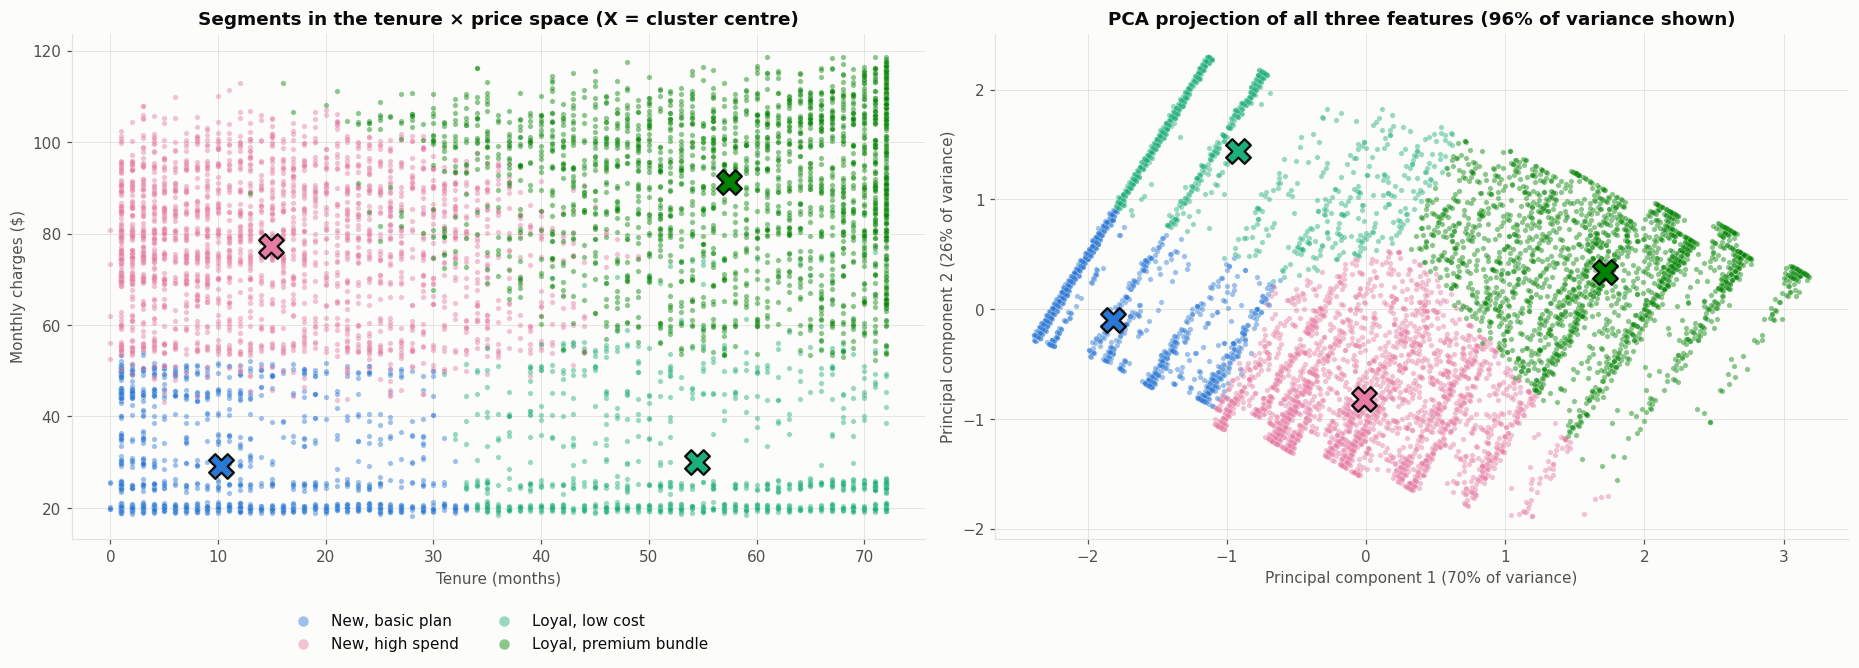

In [16]:
# ---------------------------------------------------------------
# B.4 Visualise the clusters
# ---------------------------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc)
pcs = pca.transform(Xc)
centers_pc = pca.transform(kmeans.cluster_centers_)
centers_raw = df.groupby("Segment")[cluster_features].mean()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))
ax = axes[0]
for seg in SEG_ORDER:
    m = df["Segment"] == seg
    ax.scatter(df.loc[m, "tenure"], df.loc[m, "MonthlyCharges"], s=12, alpha=0.45,
               color=SEG_COLORS[seg], edgecolor=SURFACE, linewidth=0.2, label=seg)
for seg, row in centers_raw.iterrows():
    ax.scatter(row["tenure"], row["MonthlyCharges"], s=260, marker="X", color=SEG_COLORS[seg],
               edgecolor=INK, linewidth=1.5, zorder=5)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charges ($)")
ax.set_title("Segments in the tenure × price space (X = cluster centre)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, markerscale=2)

ax = axes[1]
for seg in SEG_ORDER:
    m = (df["Segment"] == seg).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=12, alpha=0.45, color=SEG_COLORS[seg], edgecolor=SURFACE, linewidth=0.2)
for cid in range(K):
    cpc = centers_pc[cid]
    ax.scatter(cpc[0], cpc[1], s=260, marker="X", color=SEG_COLORS[CLUSTER_NAMES[cid]],
               edgecolor=INK, linewidth=1.5, zorder=5)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"Principal component 1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"Principal component 2 ({ev[1]:.0%} of variance)")
ax.set_title(f"PCA projection of all three features ({ev.sum():.0%} of variance shown)")
fig.tight_layout()
save(fig, "07_kmeans_clusters.png")
plt.show()

In [17]:
# ---------------------------------------------------------------
# B.5 Profile each segment (the churn label is used ONLY here, after clustering)
# ---------------------------------------------------------------
profile = df.groupby("Segment").agg(
    customers=("customerID", "size"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    avg_services=("NumServices", "mean"),
    avg_lifetime_revenue=("TotalCharges", "mean"),
    churn_rate=("Churn_flag", "mean"),
    pct_month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
    pct_no_internet=("InternetService", lambda s: (s == "No").mean()),
    pct_electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean()),
).reindex(SEG_ORDER)
profile["share_of_customers"] = profile["customers"] / len(df)
profile["share_of_all_churners"] = df.groupby("Segment")["Churn_flag"].sum().reindex(SEG_ORDER) / df["Churn_flag"].sum()

fmt = {"avg_tenure": "{:.1f}", "avg_monthly": "${:.2f}", "avg_services": "{:.1f}",
       "avg_lifetime_revenue": "${:,.0f}", "churn_rate": "{:.1%}", "pct_month_to_month": "{:.0%}",
       "pct_fiber": "{:.0%}", "pct_no_internet": "{:.0%}", "pct_electronic_check": "{:.0%}",
       "share_of_customers": "{:.0%}", "share_of_all_churners": "{:.0%}", "customers": "{:,}"}
profile.apply(lambda col: col.map(fmt[col.name].format)).T

Segment,"New, basic plan","New, high spend","Loyal, low cost","Loyal, premium bundle"
customers,"1,509","2,410",972,"2,152"
avg_tenure,10.3,14.9,54.5,57.4
avg_monthly,$29.21,$77.30,$30.13,$91.30
avg_services,1.7,4.2,2.1,6.7
avg_lifetime_revenue,$282,"$1,146","$1,634","$5,242"
churn_rate,23.9%,47.0%,4.1%,15.6%
pct_month_to_month,72%,86%,16%,26%
pct_fiber,0%,70%,2%,64%
pct_no_internet,58%,0%,67%,0%
pct_electronic_check,21%,53%,13%,30%


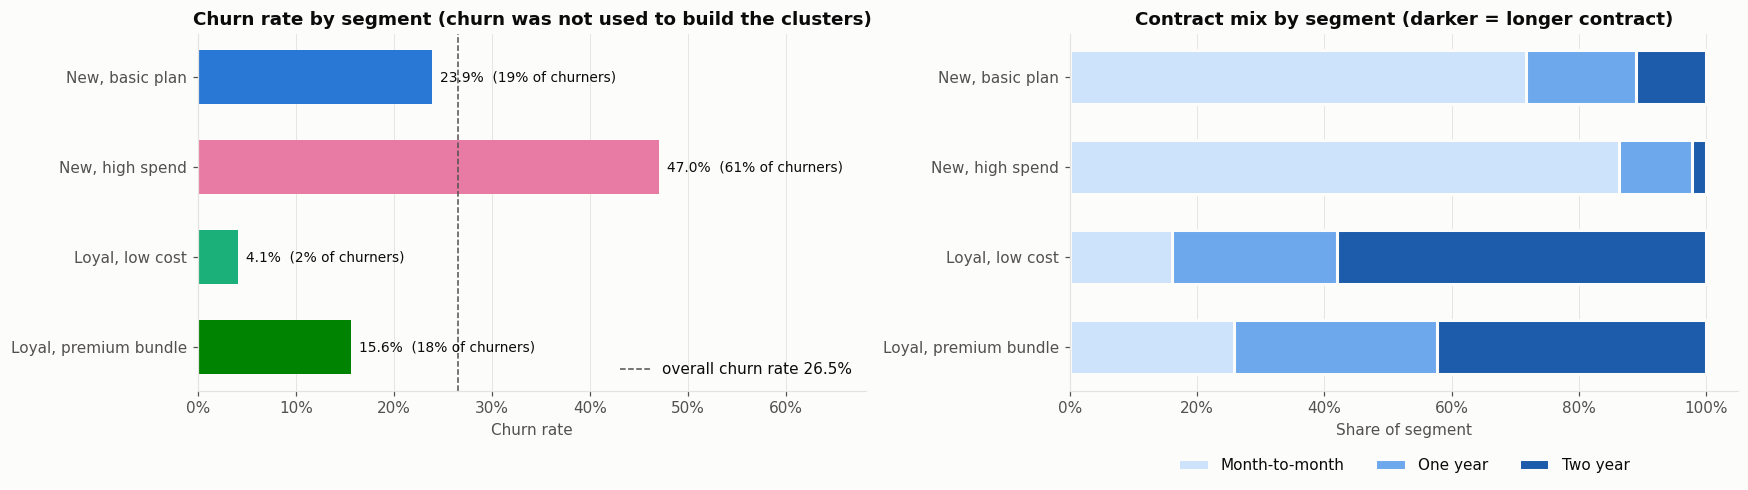

In [18]:
# ---------------------------------------------------------------
# B.6 Churn rate and contract mix per segment
# ---------------------------------------------------------------
overall = df["Churn_flag"].mean()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))

ax = axes[0]
vals = profile["churn_rate"]
ax.barh(SEG_ORDER, vals, color=[SEG_COLORS[s] for s in SEG_ORDER], height=0.6)
ax.axvline(overall, color=INK_2, ls="--", lw=1, label=f"overall churn rate {overall:.1%}")
ax.legend(loc="lower right")
for i, v in enumerate(vals):
    ax.text(v + 0.008, i, f"{v:.1%}  ({profile['share_of_all_churners'].iloc[i]:.0%} of churners)",
            va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, vals.max() * 1.45)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Churn rate")
ax.grid(axis="y", visible=False)
ax.set_title("Churn rate by segment (churn was not used to build the clusters)")

ax = axes[1]
mix = pd.crosstab(df["Segment"], df["Contract"], normalize="index").reindex(SEG_ORDER)
left = np.zeros(len(mix))
contract_cols = {"Month-to-month": "#cde2fb", "One year": "#6da7ec", "Two year": "#1c5cab"}   # light -> dark = longer
for c in ["Month-to-month", "One year", "Two year"]:
    ax.barh(mix.index, mix[c], left=left, color=contract_cols[c], height=0.6, label=c,
            edgecolor=SURFACE, linewidth=2)
    left += mix[c].values
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of segment")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_title("Contract mix by segment (darker = longer contract)")
fig.tight_layout()
save(fig, "08_segment_churn_and_contracts.png")
plt.show()

### B.7 Explaining the identified groups

| Segment | Size | Profile | Churn rate | What it means |
|---|---|---|---|---|
| **New, basic plan** | 1,509 (21%) | ~10 months, **\$29/month**, 1.7 services, 58% have no internet | 23.9% | Cheap, simple plans; average churn, low revenue (≈ \$282 to date) |
| **New, high spend** | 2,410 (34%) | ~15 months, **\$77/month**, 4.2 services, **70% fiber**, **86% month-to-month**, 53% pay by electronic check | **47.0%** | The **critical segment**: churns at almost twice the average and contains **61% of all churners** |
| **Loyal, low cost** | 972 (14%) | ~55 months, \$30/month, 2.1 services, 67% no internet, 84% on 1–2-year contracts | **4.1%** | Very stable; little retention spending needed |
| **Loyal, premium bundle** | 2,152 (31%) | ~57 months, **\$91/month**, **6.7 services**, 64% fiber | 15.6% | The **most valuable** customers (≈ \$5,242 lifetime revenue each); fewer leave, but each loss is expensive |

**Key takeaways**

* K-Means found these groups **without seeing the churn label**, yet churn rates range from **4% to 47%**. Segmentation
  on tenure, spend and engagement alone separates low-risk from high-risk customers.
* **Tenure is the main dividing line** (the first principal component explains 70% of the variance). Within each tenure
  group, spend separates basic from premium customers.
* The high-risk "New, high spend" segment matches the classification results and the Deliverable 1 EDA: new,
  month-to-month, fiber-optic customers paying by electronic check.

---
# Part C – Association Rule Mining

**Goal:** find combinations of customer attributes that frequently occur together — and especially combinations that
lead to **churn** — expressed as human-readable rules `{A, B} ⇒ {C}`.

**Each customer is treated as a "basket" of items**, for example `Contract=Month-to-month`, `Internet=Fiber optic`,
`TechSupport=No`, `Tenure=0-12`, `Churn=Yes`.

* Numeric columns are discretised first (association rules need categorical items): tenure uses the
  `tenure_group` bins from Deliverable 1, and monthly charges are split into three equal-sized bands (Low / Medium / High).
* Add-on items (`TechSupport=Yes/No`, …) are only created for internet customers, so "No" means the customer
  *chose not to buy* the add-on — not that it was unavailable.
* Very common, uninformative items (e.g. `SeniorCitizen=No`, 84% of customers) are left out so they do not flood the
  rules.

**Measures used**

* **Support** – share of all customers that contain the whole rule (how common the pattern is).
* **Confidence** – P(consequent | antecedent): of customers matching the left side, how many also have the right side.
* **Lift** – confidence ÷ overall frequency of the consequent. Lift > 1 means the items occur together **more than by
  chance**; e.g. lift 2.0 for `⇒ Churn=Yes` means those customers churn at twice the average rate.

In [19]:
# ---------------------------------------------------------------
# C.1 Build the one-hot "basket" table
# ---------------------------------------------------------------
charge_band = pd.qcut(df["MonthlyCharges"], q=3, labels=["Low", "Medium", "High"])
print("Monthly charge bands:", pd.qcut(df["MonthlyCharges"], q=3).cat.categories.astype(str).tolist())

basket_src = pd.DataFrame({
    "Contract": df["Contract"],
    "Internet": df["InternetService"],
    "Payment": df["PaymentMethod"],
    "Tenure": df["tenure_group"].astype(str) + " mo",
    "Charges": charge_band.astype(str),
    "Partner": df["Partner"],
    "Dependents": df["Dependents"],
    "PaperlessBilling": df["PaperlessBilling"],
    "Churn": df["Churn"],
})
basket_src.loc[df["SeniorCitizen"] == "Yes", "SeniorCitizen"] = "Yes"     # only the informative "Yes" item
basket_src.loc[df["MultipleLines"] == "Yes", "MultipleLines"] = "Yes"
has_internet = df["InternetService"] != "No"
for c in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    basket_src.loc[has_internet, c] = df.loc[has_internet, c]           # NaN (no item) for no-internet customers

basket = pd.get_dummies(basket_src, prefix_sep="=").astype(bool)
print(f"Transactions (customers): {basket.shape[0]:,}   Distinct items: {basket.shape[1]}")
basket.mean().sort_values(ascending=False).round(3).rename("support").to_frame().T

Monthly charge bands: ['(18.249, 50.4]', '(50.4, 83.9]', '(83.9, 118.75]']
Transactions (customers): 7,043   Distinct items: 40


,Churn=No,Dependents=No,PaperlessBilling=Yes,Contract=Month-to-month,Partner=No,OnlineSecurity=No,TechSupport=No,Partner=Yes,Internet=Fiber optic,DeviceProtection=No,OnlineBackup=No,MultipleLines=Yes,PaperlessBilling=No,StreamingTV=No,StreamingMovies=No,StreamingMovies=Yes,StreamingTV=Yes,OnlineBackup=Yes,DeviceProtection=Yes,Internet=DSL,Payment=Electronic check,Charges=Low,Charges=High,Charges=Medium,Tenure=0-12 mo,Dependents=Yes,TechSupport=Yes,OnlineSecurity=Yes,Churn=Yes,Contract=Two year,Payment=Mailed check,Tenure=25-48 mo,Payment=Bank transfer (automatic),Internet=No,Payment=Credit card (automatic),Contract=One year,Tenure=61-72 mo,SeniorCitizen=Yes,Tenure=13-24 mo,Tenure=49-60 mo
support,0.735,0.7,0.592,0.55,0.517,0.497,0.493,0.483,0.44,0.439,0.438,0.422,0.408,0.399,0.395,0.388,0.384,0.345,0.344,0.344,0.336,0.334,0.333,0.333,0.31,0.3,0.29,0.287,0.265,0.241,0.229,0.226,0.219,0.217,0.216,0.209,0.2,0.162,0.145,0.118


In [20]:
# ---------------------------------------------------------------
# C.2 Frequent itemsets with Apriori, cross-checked with FP-Growth
# ---------------------------------------------------------------
MIN_SUPPORT = 0.05     # pattern must cover at least 5% of customers (~350 people)
MAX_LEN = 4            # rules of up to 4 items stay readable

t0 = time.time()
freq_apriori = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_ap = time.time() - t0
t0 = time.time()
freq_fp = fpgrowth(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
t_fp = time.time() - t0

same = set(freq_apriori["itemsets"]) == set(freq_fp["itemsets"])
print(f"Apriori   : {len(freq_apriori):,} frequent itemsets in {t_ap:.2f} s")
print(f"FP-Growth : {len(freq_fp):,} frequent itemsets in {t_fp:.2f} s")
print("Both algorithms found exactly the same itemsets:", same)

Apriori   : 10,429 frequent itemsets in 0.70 s
FP-Growth : 10,429 frequent itemsets in 1.66 s
Both algorithms found exactly the same itemsets: True


In [21]:
# ---------------------------------------------------------------
# C.3 Generate association rules
# ---------------------------------------------------------------
def make_rules(freq, n_transactions, min_confidence):
    # mlxtend changed the signature of association_rules between versions; support both.
    try:
        return association_rules(freq, num_itemsets=n_transactions, metric="confidence",
                                 min_threshold=min_confidence)
    except TypeError:
        return association_rules(freq, metric="confidence", min_threshold=min_confidence)

rules = make_rules(freq_apriori, len(basket), min_confidence=0.5)
rules = rules[rules["lift"] > 1].copy()                          # keep positively associated rules only
rules["antecedent"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequent"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
rules["n_antecedent"] = rules["antecedents"].apply(len)
print(f"Rules with confidence >= 0.5 and lift > 1: {len(rules):,}")

cols = ["antecedent", "consequent", "support", "confidence", "lift"]

# (a) Rules that predict churn
all_churn_rules = rules[rules["consequent"] == "Churn=Yes"]

# Many churn rules are near-copies: {Fiber, first year} plus one more item that adds almost nothing.
# A rule is kept as NON-REDUNDANT only if it beats every simpler rule (subset of its left side)
# by at least 0.05 in lift - i.e. the extra item genuinely adds risk.
simpler = dict(zip(all_churn_rules["antecedents"], all_churn_rules["lift"]))
def is_non_redundant(row, tol=0.05):
    return all(row["lift"] >= lift + tol for ante, lift in simpler.items() if ante < row["antecedents"])

churn_rules = (all_churn_rules[all_churn_rules.apply(is_non_redundant, axis=1)]
               .sort_values(["lift", "support"], ascending=False))
print(f"Rules leading to Churn=Yes: {len(all_churn_rules)}   non-redundant: {len(churn_rules)}")
churn_rules[cols].head(12).round(3).reset_index(drop=True)

Rules with confidence >= 0.5 and lift > 1: 31,739
Rules leading to Churn=Yes: 331   non-redundant: 254


,antecedent,consequent,support,confidence,lift
0,"Internet=Fiber optic, PaperlessBilling=Yes, Tenure=0-12 mo",Churn=Yes,0.074,0.723,2.724
1,"Internet=Fiber optic, OnlineSecurity=No, Tenure=0-12 mo",Churn=Yes,0.085,0.717,2.701
2,"Internet=Fiber optic, Tenure=0-12 mo",Churn=Yes,0.092,0.699,2.633
3,"PaperlessBilling=Yes, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.068,0.671,2.528
4,"OnlineSecurity=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.078,0.668,2.518
5,"Payment=Electronic check, TechSupport=No, Tenure=0-12 mo",Churn=Yes,0.078,0.665,2.505
6,"OnlineBackup=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.071,0.664,2.504
7,"PaperlessBilling=Yes, TechSupport=No, Tenure=0-12 mo",Churn=Yes,0.089,0.655,2.468
8,"OnlineSecurity=No, PaperlessBilling=Yes, Tenure=0-12 mo",Churn=Yes,0.091,0.652,2.456
9,"DeviceProtection=No, Payment=Electronic check, Tenure=0-12 mo",Churn=Yes,0.069,0.642,2.418


In [22]:
# ---------------------------------------------------------------
# C.3b Broad churn patterns: two-item rules that cover the most customers
# ---------------------------------------------------------------
# The top rules above are the most *intense*; these are the most *widespread* risk patterns.
broad = all_churn_rules[all_churn_rules["n_antecedent"] == 2].sort_values("support", ascending=False)
broad[cols].head(8).round(3).reset_index(drop=True)

,antecedent,consequent,support,confidence,lift
0,"Contract=Month-to-month, TechSupport=No",Churn=Yes,0.192,0.504,1.898
1,"Contract=Month-to-month, OnlineSecurity=No",Churn=Yes,0.191,0.510,1.924
2,"Contract=Month-to-month, Internet=Fiber optic",Churn=Yes,0.165,0.546,2.058
3,"Contract=Month-to-month, OnlineBackup=No",Churn=Yes,0.163,0.503,1.896
4,"Contract=Month-to-month, Tenure=0-12 mo",Churn=Yes,0.145,0.514,1.935
5,"Contract=Month-to-month, Payment=Electronic check",Churn=Yes,0.141,0.537,2.025
6,"OnlineSecurity=No, Payment=Electronic check",Churn=Yes,0.131,0.532,2.004
7,"Payment=Electronic check, TechSupport=No",Churn=Yes,0.131,0.532,2.004


In [23]:
# ---------------------------------------------------------------
# C.4 Retention patterns: rules that lead to Churn=No with very high confidence
# ---------------------------------------------------------------
stay_rules = (rules[(rules["consequent"] == "Churn=No") & (rules["confidence"] >= 0.95)]
              .sort_values(["support", "confidence"], ascending=False))
print(f"Rules leading to Churn=No with confidence >= 95%: {len(stay_rules)}")
stay_rules[cols].head(10).round(3).reset_index(drop=True)

Rules leading to Churn=No with confidence >= 95%: 133


,antecedent,consequent,support,confidence,lift
0,Contract=Two year,Churn=No,0.234,0.972,1.323
1,"Contract=Two year, Partner=Yes",Churn=No,0.165,0.974,1.326
2,"Contract=Two year, Tenure=61-72 mo",Churn=No,0.136,0.969,1.318
3,"Contract=Two year, PaperlessBilling=No",Churn=No,0.127,0.984,1.339
4,"Contract=Two year, Dependents=No",Churn=No,0.124,0.967,1.316
5,"Contract=Two year, MultipleLines=Yes",Churn=No,0.119,0.960,1.307
6,"Contract=Two year, TechSupport=Yes",Churn=No,0.112,0.965,1.313
7,"Contract=Two year, DeviceProtection=Yes",Churn=No,0.111,0.958,1.305
8,"Contract=Two year, Dependents=Yes",Churn=No,0.110,0.977,1.330
9,"Contract=Two year, Partner=Yes, Tenure=61-72 mo",Churn=No,0.107,0.969,1.319


In [24]:
# ---------------------------------------------------------------
# C.5 Service-bundle patterns (no churn item): what do customers buy together?
# ---------------------------------------------------------------
service_prefixes = ("OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                    "StreamingTV", "StreamingMovies", "MultipleLines", "Internet")
is_service_rule = rules.apply(
    lambda r: all(i.startswith(service_prefixes) for i in r["antecedents"] | r["consequents"])
    and all(i.endswith("=Yes") or i.startswith("Internet") for i in r["antecedents"] | r["consequents"]),
    axis=1)
bundle_rules = (rules[is_service_rule & (rules["lift"] >= 1.3)]
                .sort_values(["lift", "confidence"], ascending=False))
print(f"Service-bundle rules (items bought, lift >= 1.3): {len(bundle_rules)}")
bundle_rules[cols].head(10).round(3).reset_index(drop=True)

Service-bundle rules (items bought, lift >= 1.3): 509


,antecedent,consequent,support,confidence,lift
0,"StreamingMovies=Yes, TechSupport=Yes","DeviceProtection=Yes, StreamingTV=Yes",0.100,0.574,2.580
1,"StreamingTV=Yes, TechSupport=Yes","DeviceProtection=Yes, StreamingMovies=Yes",0.100,0.579,2.556
2,"Internet=DSL, OnlineSecurity=Yes, StreamingTV=Yes",TechSupport=Yes,0.053,0.729,2.512
3,"Internet=DSL, OnlineSecurity=Yes, StreamingMovies=Yes",TechSupport=Yes,0.055,0.718,2.475
4,"Internet=Fiber optic, StreamingMovies=Yes","MultipleLines=Yes, StreamingTV=Yes",0.136,0.549,2.451
5,"MultipleLines=Yes, StreamingTV=Yes","Internet=Fiber optic, StreamingMovies=Yes",0.136,0.609,2.451
6,"OnlineSecurity=Yes, StreamingTV=Yes","DeviceProtection=Yes, StreamingMovies=Yes",0.082,0.552,2.437
7,"MultipleLines=Yes, StreamingMovies=Yes","Internet=Fiber optic, StreamingTV=Yes",0.136,0.604,2.431
8,"Internet=Fiber optic, StreamingTV=Yes","MultipleLines=Yes, StreamingMovies=Yes",0.136,0.549,2.431
9,"OnlineSecurity=Yes, StreamingMovies=Yes","DeviceProtection=Yes, StreamingTV=Yes",0.082,0.539,2.423


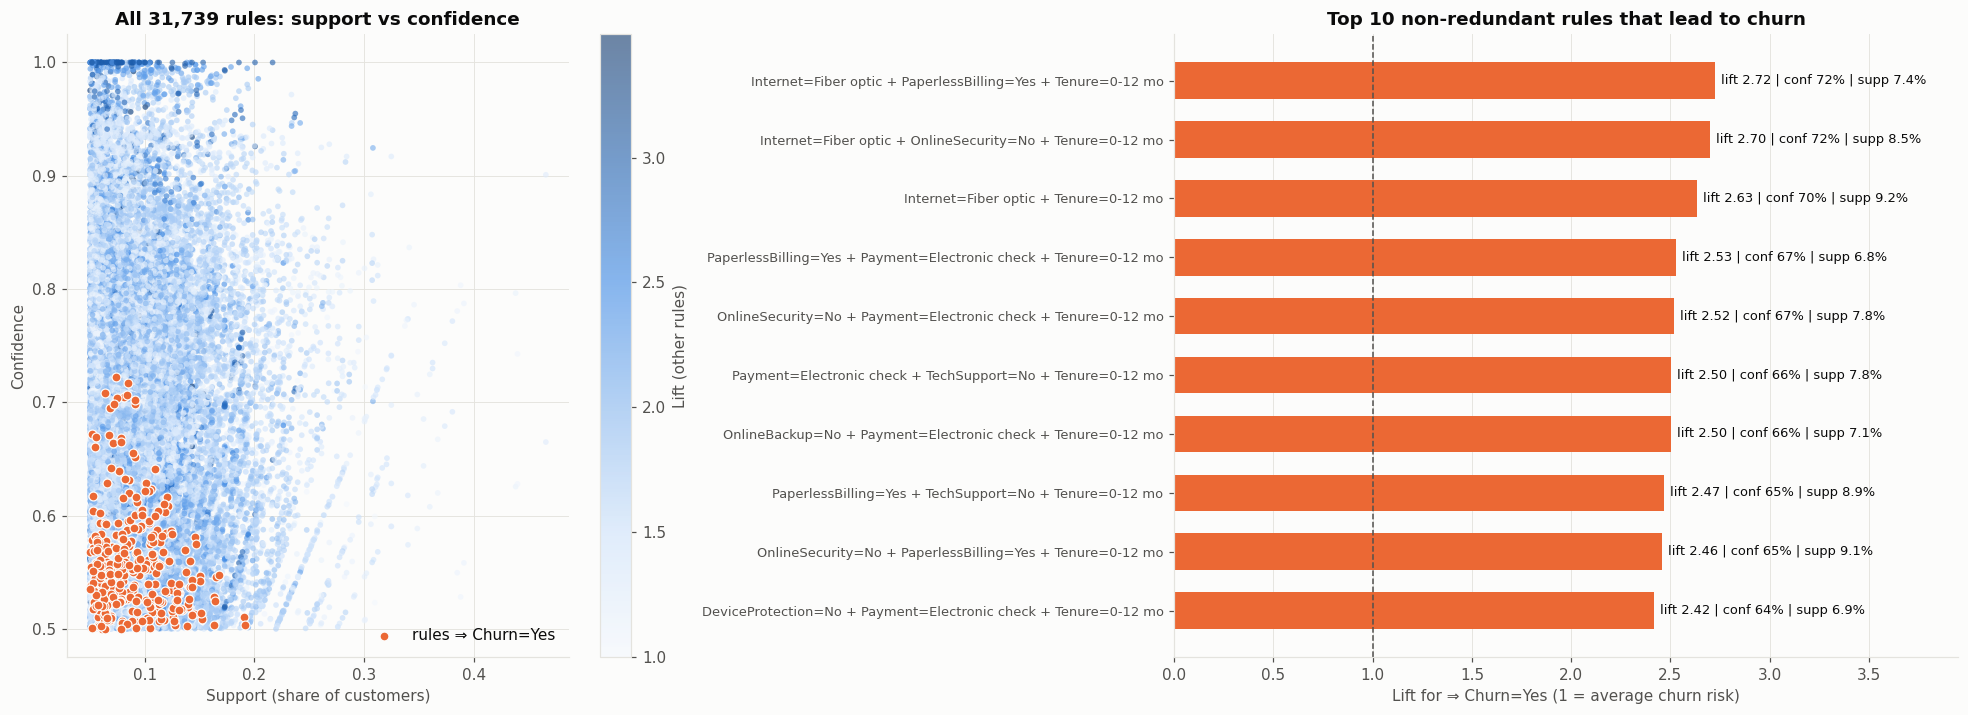

In [25]:
# ---------------------------------------------------------------
# C.6 Visualise the rules
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 6.6), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
other = rules[rules["consequent"] != "Churn=Yes"]
sc = ax.scatter(other["support"], other["confidence"], c=other["lift"], cmap=SEQ_BLUE, s=14, alpha=0.6,
                edgecolor="none", vmin=1, vmax=rules["lift"].quantile(0.99))
ax.scatter(all_churn_rules["support"], all_churn_rules["confidence"], s=34, color=CAT[1], edgecolor=SURFACE,
           linewidth=0.8, label="rules ⇒ Churn=Yes", zorder=4)
cb = fig.colorbar(sc, ax=ax)
cb.set_label("Lift (other rules)")
ax.set_xlabel("Support (share of customers)")
ax.set_ylabel("Confidence")
ax.set_title(f"All {len(rules):,} rules: support vs confidence")
ax.legend(loc="lower right")

ax = axes[1]
top = churn_rules.head(10).iloc[::-1]
labels = [a.replace(", ", " + ") for a in top["antecedent"]]
ax.barh(range(len(top)), top["lift"], color=CAT[1], height=0.62)
for i, (lift, conf, sup) in enumerate(zip(top["lift"], top["confidence"], top["support"])):
    ax.text(lift + 0.03, i, f"lift {lift:.2f} | conf {conf:.0%} | supp {sup:.1%}", va="center", fontsize=8.5)
ax.set_yticks(range(len(top)), labels, fontsize=8.5)
ax.axvline(1, color=INK_2, ls="--", lw=1)
ax.set_xlim(0, top["lift"].max() * 1.45)
ax.set_xlabel("Lift for ⇒ Churn=Yes (1 = average churn risk)")
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 non-redundant rules that lead to churn")
fig.tight_layout()
save(fig, "09_association_rules.png")
plt.show()

### C.7 Pattern-mining insights

* **Apriori and FP-Growth agree:** both found exactly the same **10,429 frequent itemsets** (minimum support 5%), which
  confirms the result. FP-Growth avoids generating candidate itemsets, so it scales better on large data. On this small
  item set (40 items) both finish in seconds.
* **31,739 rules** pass confidence ≥ 50% and lift > 1. Of these, **331 lead to churn**, and 254 remain after removing
  redundant rules.
* **Three churn "themes" dominate**, all involving the **first year** of the relationship:
  1. **Fiber optic + first 12 months → 70% churn** (lift 2.63, ≈ 9% of customers). Adding *paperless billing* or *no
     OnlineSecurity* pushes it to **72%**.
  2. **Electronic check + first 12 months** (+ paperless billing or a missing protective add-on) → **66–67% churn**
     (lift ≈ 2.5).
  3. **No protective add-ons (OnlineSecurity / TechSupport = No) + first 12 months** → **64–65% churn** (lift ≈ 2.4).
* **The most widespread risk patterns** (two-item rules with the highest support) involve month-to-month contracts:
  e.g. *{Month-to-month, Fiber optic} ⇒ Churn* covers **16.5% of all customers** with 55% confidence (lift 2.06), and
  *{Month-to-month, Electronic check} ⇒ Churn* covers 14.1% with 54% confidence.
* **Retention pattern:** *{Two-year contract} ⇒ Stay* holds with **97.2%** confidence: almost every customer on a two-year contract (24% of all customers) stays.
* **Bundle patterns (cross-selling):** add-ons are bought together. For example, customers with *StreamingTV + TechSupport*
  are 2.6× more likely than average to also have *DeviceProtection + StreamingMovies*, and DSL customers with
  *OnlineSecurity + StreamingTV* buy *TechSupport* 73% of the time (lift 2.5).

---
# Part D – Real-World Application, Challenges and Conclusion

## How these patterns can be applied

The three techniques point to the same story from different angles, which makes the findings trustworthy:
**new customers on flexible contracts, especially fiber-optic customers paying by electronic check and without
protective add-ons, are the most likely to leave.**

| Finding | Evidence | Real-world action |
|---|---|---|
| Churn can be predicted in advance | Random Forest catches 74% of churners (ROC-AUC 0.84); tuned tree and logistic regression catch 78% | **Score every customer monthly** and send the highest-risk list to the retention team. Combine with the Deliverable 2 value model to rank by **revenue at risk**. |
| The first year is the danger zone | All top churn rules include *Tenure = 0–12 months*; the "New, high spend" segment churns at 47% | Run a **12-month onboarding programme**: welcome calls, a 3-month check-in, and early-life satisfaction surveys. |
| Fiber-optic customers churn most | Rule {Fiber, first year} ⇒ churn 70%; fiber is a top split in the decision tree | **Investigate fiber service quality and pricing** (fiber is the premium product, yet it churns most); offer first-year price locks. |
| Contracts retain customers | {Two-year contract} ⇒ stay 97%; contract is the tree's first split | **Offer incentives to move month-to-month customers to 1- or 2-year contracts** (e.g. a discount or free add-on). |
| Electronic-check payers churn more | Electronic-check rules at lift 2.0–2.5 | **Encourage automatic payment** with a small bill credit for switching. |
| Protective add-ons are linked to staying | "No TechSupport / No OnlineSecurity" appear in many churn rules | Include a **free trial of OnlineSecurity / TechSupport** for new internet customers. |
| Add-ons are bought in bundles | Bundle rules with lift ≈ 2.4–2.6 | Design **"protection" and "entertainment" bundles** for cross-selling to customers who own one item. |
| Segments need different strategies | 4% churn (Loyal, low cost) vs 47% (New, high spend) | **Spend the retention budget where it matters**: proactive outreach for New/high-spend, VIP care for Loyal/premium, minimal spend for Loyal/low-cost. |

**Caution:** these are associations, not proof of cause and effect. For example, auto-pay customers may stay longer
because they are already committed, not *because* of auto-pay. Each action should be tested (e.g. an A/B test of the
onboarding programme) before full rollout. Using `SeniorCitizen` as a model input also needs a fairness review; this
will be discussed under ethical considerations in Deliverable 4.

## Challenges Encountered and How They Were Addressed

| Challenge | How it was addressed |
|---|---|
| **Class imbalance** (only 26.5% churners): accuracy rewards predicting "stay" for everyone. | Stratified split and folds, `class_weight="balanced"`, and model selection by **F1 / recall / ROC-AUC** rather than accuracy. |
| **Overfitting of the default Decision Tree** (near-perfect training score, weak test score). | `GridSearchCV` over depth, leaf size, criterion and class weight with 5-fold CV; the heatmaps show the train–validation gap closing for the chosen settings. |
| **Different feature scales** would distort k-NN distances and K-Means clusters. | `StandardScaler` inside every pipeline (fitted on training folds only) and on the clustering features. |
| **Choosing the number of clusters** has no single right answer. | Combined the elbow curve, silhouette scores and business interpretability; profiled clusters with churn only *after* clustering. |
| **K-Means labels are arbitrary** (cluster "0" can change between runs or library versions). | Re-numbered clusters by average tenure and spend so segment names stay attached to the right group. |
| **Association rules need categorical items** and can explode in number. | Binned tenure and charges, created add-on items only for internet customers, dropped uninformative items, and used minimum support (5%), confidence (50%), lift > 1 and a maximum rule length of 4. |
| **Library version differences** (`mlxtend` changed `association_rules`' arguments; Random Forest scores vary slightly across scikit-learn versions). | Wrote a small wrapper for `association_rules` that works with old and new `mlxtend` versions (Section C.3), and tested the notebook on old and new library versions; Random Forest F1 stayed between 0.63 and 0.64, so the model ranking and conclusions are unchanged (see the note in Section A.5). |

## Conclusion

* **Classification:** six classifiers were compared with confusion matrices, ROC curves, accuracy and F1. **Random
  Forest** performed best (F1 0.636, ROC-AUC 0.843, 74% of churners caught). **GridSearchCV tuning** of the Decision
  Tree (`max_depth=4`, `min_samples_leaf=40`, `gini`, `balanced`) raised its test F1 from 0.499 to 0.621 and removed
  overfitting.
* **Clustering:** K-Means with **k = 4** (best silhouette, 0.427) found four interpretable segments. Churn ranges from
  4% (Loyal, low cost) to 47% (New, high spend), even though churn was not used to form the clusters.
* **Association rules:** Apriori (confirmed by FP-Growth) found that **fiber optic, electronic-check payment and missing
  protective add-ons in the first year** lead to churn rates of 64–72% (lift ≈ 2.4–2.7), while **two-year contracts**
  lead to 97% retention.

Together, the models give the business **who** is likely to leave (classification), **which group** they belong to
(clustering) and **why** (association rules). Deliverable 4 will consolidate these results into final
recommendations, with ethical considerations.